# OpenCV Image Analyzer

This project demonstrates image processing techniques
using Python and OpenCV.

In [15]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [16]:
import cv2

In [17]:
photo = cv2.imread("../images/sample.jpg")

In [33]:
print(type(photo))
print(photo is None) #To check image is loaded or not

<class 'numpy.ndarray'>
False


Shape Details

In [20]:
print(photo.shape)

(6000, 4000, 3)


In [25]:
#We can Extract Information as below:
#height = photo.shape[0]
#width = photo.shape[1]
#channels = photo.shape[2]

#But we don't need to becuase .shape is a tuple having all this information
height, width, channels = photo.shape #like this we can extract

#Lets call those details directly
print(f"Height: {height}")
print(f"Width: {width}")    
print(f"Channels: {channels}")

Height: 6000
Width: 4000
Channels: 3


In [26]:
pixel_count = height * width
print(f"Total Pixel: {pixel_count}")

Total Pixel: 24000000


In [27]:
from matplotlib import pyplot as plt

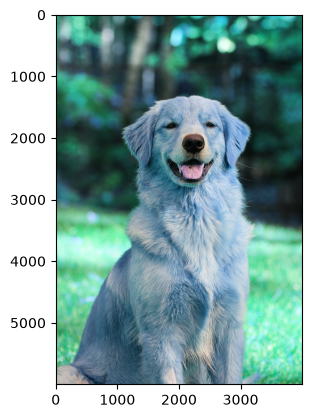

In [31]:
plt.imshow(photo)
#plt.show()

Note: OpenCV uses BGR instead or RGB

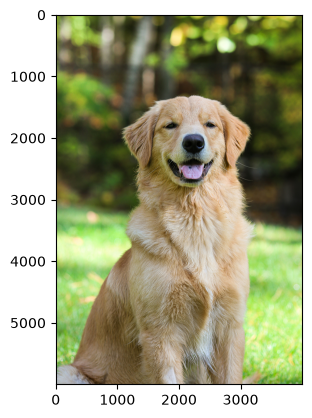

In [39]:
photo_rgb = cv2.cvtColor(photo, cv2.COLOR_BGR2RGB)
plt.imshow(photo_rgb)
plt.show()

In [36]:
aspect_ratio = width/height
print(f"Aspect Ratio: {aspect_ratio: .2f}")

Aspect Ratio:  0.67


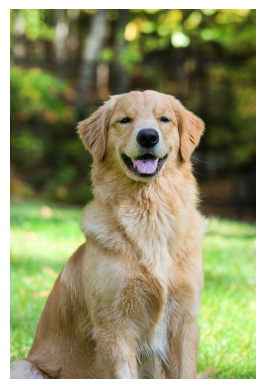

In [40]:
plt.imshow(photo_rgb)
plt.axis("off")
plt.show()

## Grayscale Conversion

Converting the image from color to grayscale simplifies processing
by reducing the number of channels from 3 to 1.

In [41]:
photo_gray = cv2.cvtColor( photo, cv2.COLOR_BGR2GRAY)


In [44]:
print(f"Original Shape: {photo.shape}")
print(f"Gray Shape: {photo_gray.shape}")

Original Shape: (6000, 4000, 3)
Gray Shape: (6000, 4000)


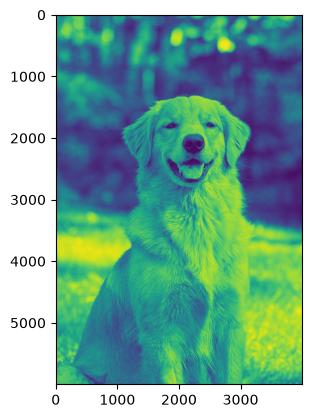

In [ ]:
plt.imshow(photo_gray) #Need to use cmap to get the correct gray image
plt.show()

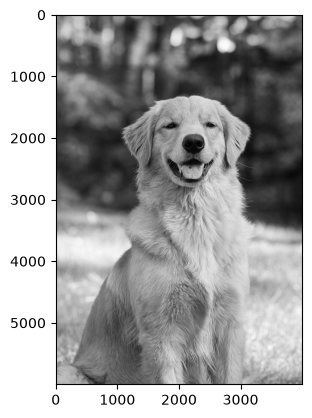

In [49]:
plt.imshow(photo_gray, cmap="gray")
plt.show()

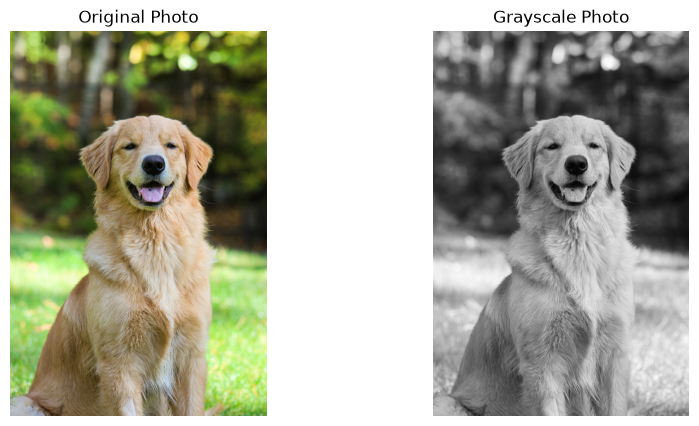

In [59]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(photo_rgb)
plt.title("Original Photo")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(photo_gray, cmap="gray")
plt.title("Grayscale Photo")
plt.axis("off")

plt.savefig("../images/outputs/comparision_original_gray.png", bbox_inches="tight")
plt.show()

In [60]:
cv2.imwrite("../images/outputs/gray_dog.jpg", photo_gray)

True

In [54]:
print(f"Original Channels : {photo.shape[2]}")
print(f"Gray Dimensions : {len(photo_gray.shape)}")

Original Channels : 3
Gray Dimensions : 2


## Image Blurring(Noise Reduction)

Gaussian Blur reduces image noise and helps improve edge detection results

In [61]:
photo_blur = cv2.GaussianBlur(photo_gray, (5,5),0)
#(5,5) - Kernel Size(Blur Setting), Light blur - (3,3), Heavy blur - (15,15)
#0 - sigma value, 0 is its default value where OpenCV calculate automatically

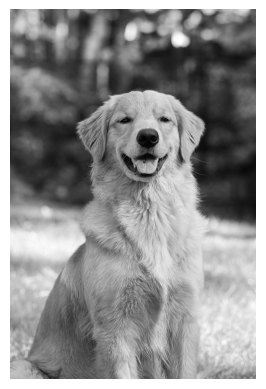

In [67]:
plt.imshow(photo_blur, cmap="gray")
plt.axis("off")
plt.show()

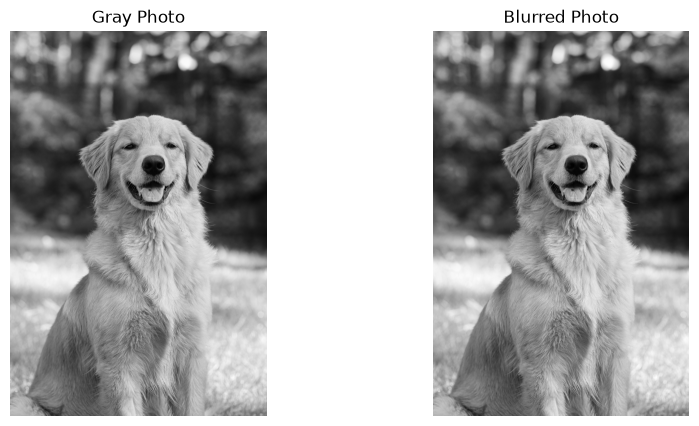

In [69]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(photo_gray, cmap="gray")
plt.title("Gray Photo")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(photo_blur, cmap="gray")
plt.title("Blurred Photo")
plt.axis("off")

plt.savefig("../images/outputs/gray_vs_blur.png", bbox_inches="tight")
plt.show()

In [70]:
cv2.imwrite("../images/outputs/blurred_dog.jpg", photo_blur)

True

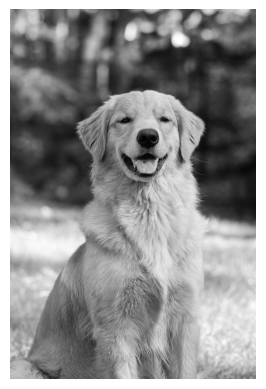

In [71]:
extra_blur = cv2.GaussianBlur(photo_gray, (15,15),0)

plt.imshow(extra_blur, cmap="gray")
plt.axis("off")
plt.show()

## Canny Edge Detection

Canny Edge Detection identifies the boundaries of objects in an image and is commonly used before image analysis and object recognition

In [79]:
photo_edge = cv2.Canny(photo_blur, 100, 200)
#100 -- Lower Threshold, weak edges below this value are ignore
#200 -- Higher Threshold, strong edges above this value are definitely kept

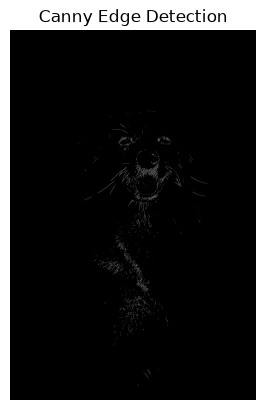

In [80]:
plt.imshow(photo_edge, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

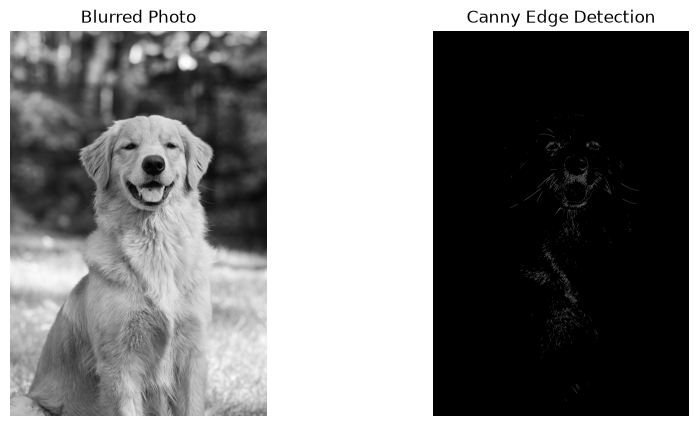

In [81]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(photo_blur, cmap="gray")
plt.title("Blurred Photo")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(photo_edge, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.savefig("../images/outputs/blur_vs_edge.png", bbox_inches="tight")
plt.show()


In [82]:
cv2.imwrite("../images/outputs/edge_dog.jpg", photo_edge)

True

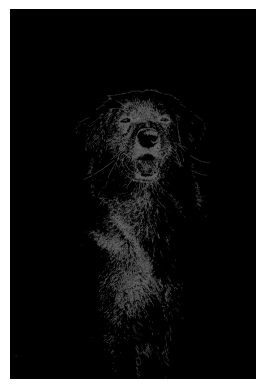

In [83]:
photo_edge_2 = cv2.Canny(photo_gray, 50, 150)
plt.imshow(photo_edge_2, cmap="gray")
plt.axis("off")
plt.show()

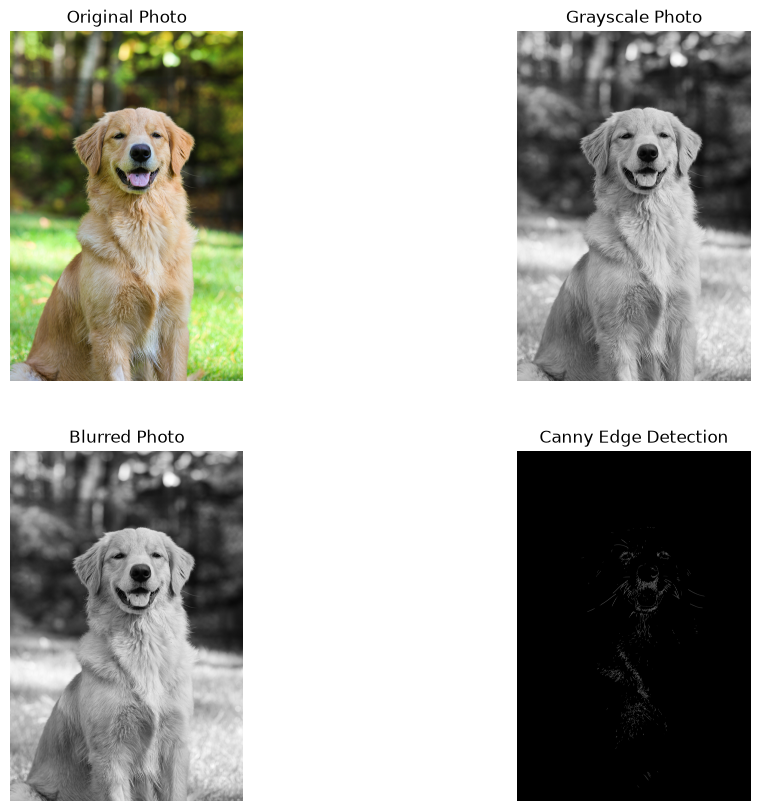

In [84]:
plt.figure(figsize=(12,10))

plt.subplot(2,2,1)
plt.imshow(photo_rgb)
plt.title("Original Photo")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(photo_gray, cmap="gray")
plt.title("Grayscale Photo")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(photo_blur, cmap="gray")
plt.title("Blurred Photo")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(photo_edge, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.savefig("../images/outputs/final_comparision.png", bbox_inches="tight")
plt.show()